# Training Data
Actually this data is not used, yet. Instead, I generate Data with a DDM with exemplar parameters, to make the strengths and weaknesses of my approaches more tractable. Also, this data is not even actually behavioural, so I might kick it our of the project in the future. Still, thanks a lot to the authors for sharing this data.

In [2]:
# get data from: https://www.frontiersin.org/journals/psychology/articles/10.3389/fpsyg.2022.1039172/full#h16
import pandas as pd

df = pd.read_csv("data/empdata1.csv")
df

,cond,response,rt
0,s1,lower,0.437543
1,s1,lower,0.478732
2,s1,lower,0.352887
3,s1,lower,0.346259
4,s1,lower,0.256688
...,...,...,...
495,s2,upper,0.406501
496,s2,upper,0.482574
497,s2,upper,0.463195
498,s2,upper,0.466468


In [4]:
#the data gets changed so it works with the code of a previous project
df.rename(columns={"cond": "plausible",}, inplace=True)

In [13]:
df.loc[df["response"]=="lower","response"]=-1
df.loc[df["response"]=="upper","response"]=1

In [36]:
df.loc[:,"rt"]=(df["rt"]*1000).astype("int")

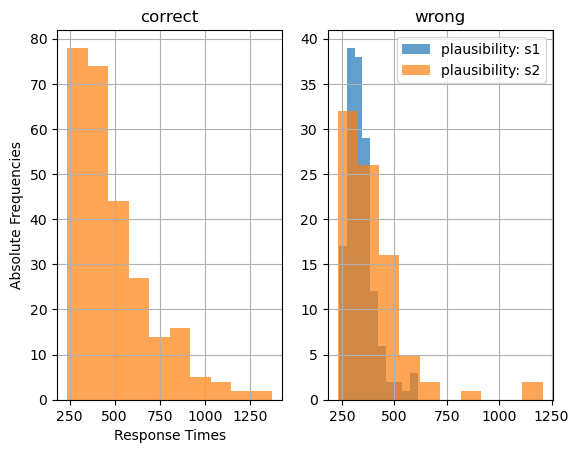

In [38]:
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
ddm.plot_histogram(conditions=["s1", "s2"])

# Architecture
The following two cells introduce an implementation of nodes of a neural network in a graph representation. An implementation of the operations l2-Loss and a specific linear layer that represents a single step of a DDM are given.

In [2]:
class Node:
    """
    A class representing a computational node in a neural network.

    Attributes:
        free_params_dict (dict): A dictionary mapping parameter names to their indices.
        free_params (np.ndarray): An array of free parameters.
        constants (any): Constants used in the operation of the node.
        memory (list): A list to store inputs for the forward pass.
        operation (function): The operation function for the forward pass.
        derivative (function): The derivative function for the backward pass.
        gradients (list): A list to store gradients calculated during backpropagation.
    """
    def __init__(self, free_params, constants, operation, derivative):
        """
        Initializes the Node with free parameters, constants, operation, and derivative functions.

        Args:
            free_params (dict): A dictionary of free parameters i.e. named trainable weights for the node.
            constants (dict): Constants used in the operation of the node. Not used, yet.
            operation (function): The operation function for the forward pass.
            derivative (function): The derivative function for the backward pass.
        """
        self.free_params_dict = dict(zip(free_params, np.arange(len(free_params))))
        self.free_params = np.array(list(free_params.values()))
        self.constants = constants
        self.memory = []
        self.operation = operation
        self.derivative = derivative
        self.gradients = []

    def forward(self, x):
        """
        Performs the forward pass through the node.

        Args:
            x (any): The input to the node.

        Returns:
            any: The result of the operation function applied to the input.
        """
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x)

    def back(self, df, t):
        """
        Performs the backward pass through the node, calculating the gradient.

        Args:
            df (float): The gradient of the next operation (i.e., the derivative of all subsequent operations).
            t (int): The time step to use from the memory.

        Returns:
            any: The gradient of the current node with respect to its inputs.
        """
        x = self.memory[t]
        self.gradients.append(self.derivative(self.constants, self.free_params, x, df))
        return self.gradients[-1]

    def update(self, lr, v=False):
        """
        Updates the free parameters of the node using the accumulated gradients.

        Args:
            lr (float): The learning rate for the update step.
            v (bool, optional): Whether to print the update values. Defaults to False.
        """
        self.free_params -= lr * np.sum(self.gradients, axis=0)
        if v:
            print(lr * np.sum(self.gradients, axis=0))
        self.gradients = []


In [3]:
def ddm_forward(_, free_params, x):
    """
    Computes the forward pass for the drift-diffusion model.

    Args:
        _ (any): Unused constant.
        free_params (list): Free parameters for the model.
        x (list): Inputs to the function. Expects:
            x[0] (float): z
            x[1] (float): noise

    Returns:
        float: Result of the operation.
    """
    return x[0] + x[1] * free_params[0] + free_params[1]

def ddm_backward(_, free_params, x, df):
    """
    Computes the backward pass for the drift-diffusion model, providing derivatives.

    Args:
        _ (any): Unused constant.
        free_params (list): Free parameters for the model.
        x (list): Inputs to the function.
        df (float): Derivative of previous functions.

    Returns:
        tuple: Gradients with respect to the inputs.
    """
    return df * x[1], df * 1

def l2_forward(_, __, x):
    """
    Computes the forward pass for the L2 loss function.

    Args:
        _ (any): Unused constant.
        __ (any): Unused free parameter.
        x (list): Inputs to the function. Expects:
            x[0] (float): y (predicted value)
            x[1] (float): true (true value)

    Returns:
        float: L2 loss.
    """
    return 1/2 * (x[0] - x[1]) ** 2

def l2_backward(_, __, x, ___):
    """
    Computes the backward pass for the L2 loss function, providing the gradient.

    Args:
        _ (any): Unused constant.
        __ (any): Unused free parameter.
        x (list): Inputs to the function.
        ___ (float): Unused derivative of previous functions.

    Returns:
        float: Gradient with respect to the input.
    """
    return x[0] - x[1]


# Test training after one iteration
As a proof of concept, I want to see if the implementation in general is able to minimize a loss by iteratively improving parameters. For that, we simply fit it so that the z value after one iteration predicts the same for a white-box true model (in behavioural data we of course don't have access to intermediate z-values). Note, that the squared error is minimized, when predicting the mean of the dataset, so the model should do exactly that and "unlearn" the noise.

In [140]:
sigma=0.4
drift=0.8

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backwards)

In [126]:
z0=0.5
def generate_data(model, n=100):
    data=np.zeros((n,))
    
    for i in range(n):
        data[i]=model.forward([z0, np.random.random()-0.5])
        
    return data

print(generate_data(ddm_net))

[1.20155037 1.15902519 1.29739059 1.46967489 1.12229465 1.23737061
 1.44342158 1.45405755 1.36553133 1.40472914 1.4023621  1.39690213
 1.47791964 1.19294809 1.25769428 1.32304945 1.46095756 1.25666653
 1.26237192 1.49663703 1.24018687 1.12718738 1.17016592 1.3212127
 1.25460818 1.4199906  1.17654016 1.37974258 1.20536413 1.23139654
 1.45574375 1.1419589  1.17076508 1.4787268  1.49966265 1.12240364
 1.34668136 1.40035386 1.29488394 1.40100867 1.10538175 1.23266451
 1.1967058  1.12367103 1.38576478 1.25497823 1.34779944 1.19501311
 1.35243066 1.35283598 1.35595967 1.24678692 1.33624539 1.24439532
 1.21835749 1.38648399 1.2093304  1.19864726 1.45458225 1.28505845
 1.47423963 1.16067103 1.10182356 1.16939164 1.28525443 1.26520417
 1.11916366 1.40463778 1.40445466 1.13501733 1.47878799 1.32509657
 1.1791358  1.21745797 1.28753475 1.33624054 1.26740685 1.27098314
 1.44479203 1.38501656 1.13679438 1.13276202 1.48301838 1.38619731
 1.38830381 1.28995436 1.15660007 1.16839461 1.40191077 1.43541

original params:
  sigma: 0.4
  drift: 0.8

init params:
  sigma: 0.22722778989323278
  drift: -0.4998283256401056

train params:
  sigma: 0.28020220861608475
  drift: -0.3886267874287764

train params:
  sigma: 0.3634717318190628
  drift: 0.6009202742049633

train params:
  sigma: 0.18734335387601037
  drift: 0.6962433372692878

train params:
  sigma: 0.09550696188424015
  drift: 0.7434809998922919

train params:
  sigma: 0.051460363084351826
  drift: 0.7673510328988649

train params:
  sigma: 0.02606316830523402
  drift: 0.7806132778041555

train params:
  sigma: 0.011183063928815786
  drift: 0.787394410659254

train params:
  sigma: 0.005445295301609511
  drift: 0.7908440460671725

train params:
  sigma: 0.003749971894678469
  drift: 0.7918320890768767

train params:
  sigma: 0.0018815077145293198
  drift: 0.7933194028588879



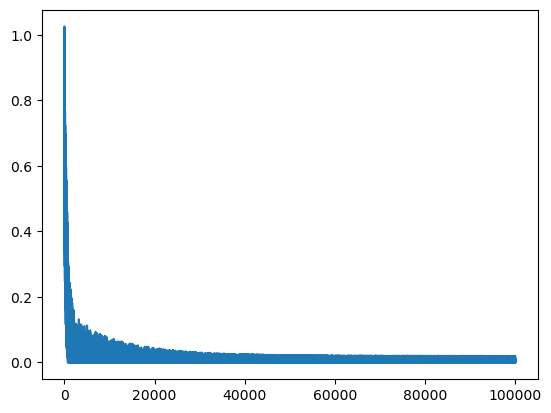

In [128]:
import matplotlib.pyplot as plt

epochs=1000

#true model

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backwards)

train_data=generate_data(ddm_net)

print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backwards)
loss_function=Node({},{},l2_forward,l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

for epoch in range(epochs):
    for true in train_data:
        y = train_model.forward([z0, np.random.random()])#for now lets not train z0
        losses.append(loss_function.forward([y, true]))
        d_activation=loss_function.back(None)
        _=train_model.back(d_activation)
        train_model.update(0.001)
    losses_smooth.append(np.mean(losses[-len(train_data):]))
    if not epoch%(epochs/10):
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

plt.plot(np.arange(len(losses)), losses)
plt.show()
# qed! nice :D

# Maximize rewards over time
At each toimestep before reaching any of the two thresholds, a "reward" is given for z being as close as possible to the ratio of positive examples at this timestep as well as 1-z being as close as possible to the ratio of negative examples at the given timestep. The updates are accumulated and applied after a threshold is reached. The training signal of each timestep is backpropagated through all previous recurrent steps. The training signal is called "reward" because the respective parts are not supposed to be minimized (they are definitely different from the z-values) but rather supposed to bee seen as incentives that push differently hard in opposing directions. This is mainly a testbed for backpropagation in an RNN.

In [6]:
# nr = negative reward, preliminary name for new update

def nr_forward(_, __, x):
    """
    x[0]=y, x[1]=t,pos , x[2]=t,neg (convention: inputs first, constants last)
    """
    return -(x[0]*x[1]+(1-x[0])*x[2])

'''
f=-(x[0]*x[1]+(1-x[0])*x[2])
f=-x[0]*x[1]-(1-x[0])*x[2]
f=-x[0]*x[1]-(x[2]-x[0]*x[2])

a=-x[0]*x[1]
b=-x[2]+x[0]*x[2]

sum rule:
df/dx[0] = da/dx[0] + db/dx[0]
da/dx[0] = -x[1]
db/dx[0] = x[2]
'''

def nr_backward(_, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return -x[1]+x[2]


def weighted_distance(_, __, x):
    """
    nope
    """
    return (1-x[0])*x[1]+x[0]*x[2]

In [5]:

import warnings
warnings.filterwarnings("error")

import numpy as np
import pandas as pd
from tqdm import tqdm

     response    rt
0         1.0  13.0
1         1.0  30.0
2        -1.0   9.0
3         1.0  10.0
4         1.0  20.0
..        ...   ...
995      -1.0   8.0
996       1.0  18.0
997       1.0  77.0
998       1.0  92.0
999      -1.0  15.0

[1000 rows x 2 columns]


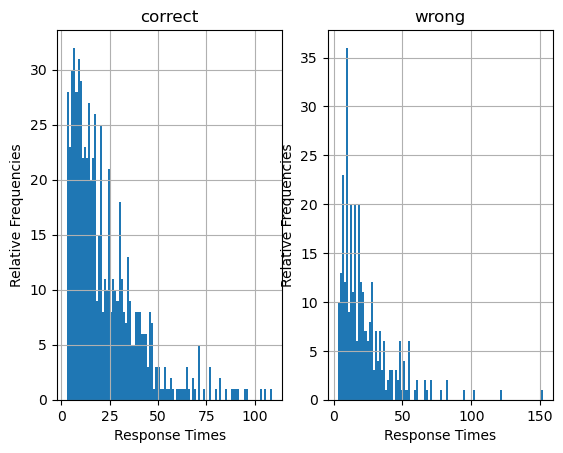

original params:
  sigma: 0.4
  drift: 0.01

init params:
  sigma: 0.48548635305127275
  drift: -0.46401830616052797



 33%|█████████████████████████▌                                                   | 332/1000 [00:00<00:00, 3245.56it/s]

train params:
  sigma: 0.5014005073840675
  drift: -0.4393857458758042

train params:
  sigma: 0.5256374767160392
  drift: -0.3974480995802735

train params:
  sigma: 0.5938936596181452
  drift: -0.2649911821422795

train params:
  sigma: 0.6332970627280881
  drift: -0.17773672148800757

train params:
  sigma: 0.6496622329656576
  drift: -0.1403151263386943

train params:
  sigma: 0.6598325916732983
  drift: -0.11630336921924961

train params:
  sigma: 0.6678763495675066
  drift: -0.0975356599811452

train params:
  sigma: 0.6729609891642417
  drift: -0.08554722691484032



100%|████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 4188.10it/s]

train params:
  sigma: 0.677625378234947
  drift: -0.07542474472138498

train params:
  sigma: 0.6817882651921195
  drift: -0.06505510857021081



'\nplt.plot(np.arange(len(losses)), losses)\nplt.show()'

In [7]:
# right now:
# a: gradients are averaging each other out
# b: gradients are too small (after all there are many 0 updates...)
# todo: plot output dist

import warnings
warnings.filterwarnings("error")

import numpy as np
import pandas as pd
from tqdm import tqdm
# todo: maximize CE(y_distribution, true_distribution)
# first draft (definitely biased): run until threshold, maximize z_t*true_t,pos + z_t*true_t,neg for each t, starting with the last

# generate dataset over t
z0=0.5
sigma=0.4
drift=0.01
max_steps=200
epochs=1000
lr=0.01

def generate_data_t(model, max_steps, n=1000):
    data=np.zeros((n,2))
    
    for i in range(n):
        z=z0
        
        run=True
        t=0
        while t<=max_steps:
            t+=1
            z = model.forward([z, np.random.random()-0.5])
            if z>=1:
                data[i]=[t,1]
                break
                
            elif z<=0:
                data[i]=[t,-1]
                break

    return data

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]/len(dataset)
data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]/len(dataset)



print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function=Node({},{},nr_forward, nr_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

for epoch in tqdm(range(epochs)):
    z=z0
    for t in range(max_steps):
        z = train_model.forward([z, np.random.random()-0.5])#for now lets not train z0

        loss = loss_function.forward([z, data_dist[0,t], data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))
        
        derivative=loss_function.back(None,-1)
        #print(derivative)
        #print(t)
        for t_back in range(t, 0-1, -1):
            #print(t_back)
            #print(train_model.memory)
            derivative=train_model.back(derivative, t_back)[0]
        
        if z>=1 or (z<=0):
            train_model.memory=[]
            break
        
    train_model.update(lr)
    
    if not (epoch+1)%(epochs/10):
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

'''
plt.plot(np.arange(len(losses)), losses)
plt.show()'''

     response    rt
0         1.0   6.0
1        -1.0   3.0
2        -1.0  11.0
3        -1.0  12.0
4         1.0   7.0
..        ...   ...
995      -1.0   6.0
996      -1.0  16.0
997      -1.0  11.0
998      -1.0   3.0
999      -1.0   6.0

[1000 rows x 2 columns]


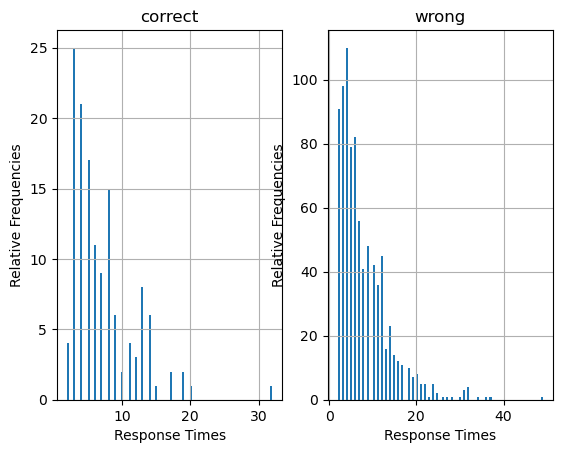

In [8]:
from ddm import DDM
predictions=generate_data_t(train_model, max_steps, n=1000)
df=pd.DataFrame()
df["response"]=predictions[:,1]
df["rt"]=predictions[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

In [12]:
train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function=Node({},{},nr_forward, nr_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

condition=True
while(condition):
    for t in range(max_steps):
        z = train_model.forward([z0, np.random.random()])#for now lets not train z0
        print("z:",z)

        loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))

        derivative=loss_function.back(None,-1)
        if derivative>0:
            print("----start-----")
            condition=False
        #print(derivative)
        #print(t)
        for t_back in range(t, 0-1, -1):
            #print(t_back)
            #print(train_model.memory)
            derivative=train_model.back(derivative, t_back)[0]
            print(t_back, derivative)

        if z>=1 or (z<=0):
            train_model.memory=[]
            break
    train_model.update(lr, v=True)

init params:
  sigma: 0.11063234201886463
  drift: -0.26642204383055534

z: 0.31836821664611636
0 0.0
z: 0.29924962975536085
1 0.0
0 0.0
z: 0.2638698449440907
2 -0.001369034055587504
1 -0.0008126625179029018
0 -0.0006228365531741641
z: 0.2916909191054652
3 -0.0021011202285173116
2 -0.0005753010295447997
1 -0.0003415003310647198
0 -0.0002617308961868469
z: 0.3187545038973181
4 -0.010778689544391018
3 -0.005661830659657003
2 -0.0015502477980079803
1 -0.0009202315119633416
0 -0.0007052790185433144
z: 0.2632662994883096
5 -0.004830325110973854
4 -0.0037188981978330897
3 -0.00195346305781592
2 -0.0005348714904964192
1 -0.0003175012414389975
0 -0.00024333763953662612
z: 0.2632927769366431
6 -0.003760270126703475
5 -0.0010090737342811462
4 -0.0007768923220868421
3 -0.0004080860433291126
2 -0.0001117367381855026
1 -6.632724629857387e-05
0 -5.083418092511742e-05
z: 0.3361342895469336
7 -0.002781004130600473
6 -0.0007469519110382804
5 -0.0002004455873654508
4 -0.00015432433976823574
3 -8.1063498

# Optimize z=1 at mean(z_t-1, z_t), Noiseless eval (optional)

Here the actually meaningful ideas start happening. In this approach, we assume that a meaningful training signal can be achieved, by finding the timestep at which the model reaches z=1 (or z=0 for lower threshold) and comparing that value with the cumulative train distribution, that has been rescaled so that it has the value zero at the timestep of the mode. More precisely, the (cumulative) train distribution gets divided by the (cumulative) frequency at the t value, where before summing up the highest amount of reactions got sampled.

The idea behind this is, that whenever the output of the model maximizes the likelihood p(t|correct vs wrong), the gradient will be exactly zero. Fo simplicity, lets only consider the case where the upper threshold is reached during training: In cases where the train model is "too fast", i.e. predicts a reaction time that is lower than the one where the mode is, the gradient will be positive and hence decrease all values that have lead to this outcome. This results in the drift getting smaller and the noise parameter getting smaller at time steps where positive noise gets sampled, and bigger at time steps where negative noise was sampled. In other words: the gradient for the noise parameter is random. However, gradients for noise are on average bigger in "bad" runs, where the model predicted a t that is too high or too low. So in truth, the noise parameter is rather optimized by random search than by gradient descent, where the stepsize through parameter space simply decreases for "good" values.

Of course we cannot make sure, that the z value where a threshold is reached, is precisely one (or zero for lower threshold). Two tricks were experimented with in order to solve this problem: First (and also turning out to be the better approach) the mean between the timestep just before and just after reaching the threshold is reached is compared to the value at t. Secondly, I substracted the difference between the found z value and 1 from the output value, but assuming the difference as a constant wrt backpropagation. That is an idea loosely based on the "straight through" trick in Gumbel Softmax sampling. However, it seemed that assuming variable values as a constant has lead to a bias that is too big.

Optionally the experiment can be run with training data that was generated without noise. This serves the purpose of prooving, that the model can actually find the correct drift rate in a noiseless scenario.

So far we can find the correct drift, but oscillate around the correct value (feels like reaching correct value, still go one step further due to loss minimum not being zero and then get elephanted several steps back)

todos:
- remove the bias of the loss and bias the gradients instead, by assuming we get the correct value at the t with z=1
- make elephant less aggressive
- finally do the CE thingnoise_replacement

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless

import pandas as pd
from tqdm import tqdm

In [2]:
class Node:
    def __init__(self, free_params, constants, operation, derivative):
        self.free_params_dict=dict(zip(free_params,np.arange(len(free_params))))
        self.free_params=np.array(list(free_params.values()))
        self.constants=constants
        self.memory=[]
        self.operation=operation
        self.derivative=derivative
        self.gradients=[]
        
    def forward(self,x):
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x)
    
    def back(self, df, t=None, v=False):
        """
        params:
            df (float): gradient of the next operation aka derivative of all that happens after this node
        """
        x=self.memory[t]
        #x=self.memory.pop()
        gradients=self.derivative(self.constants, self.free_params, x, df)
        self.gradients.append(gradients[:len(self.free_params)])
        if v==True:
            print(f"gradient at {t}: {self.gradients[-1]}")
            print(f"for inputs x",x)
        return gradients
    
    def update(self, lr, v=False):
        """
        terrible efficiency, todo: use dict only for mapping index to name and work on an array
        """
        #for key in np.arange(len(self.free_params)):
        #print(self.gradients)
        self.free_params-=lr*np.sum(self.gradients, axis=0)
        if v:
            print("updates:",-lr*np.sum(self.gradients, axis=0))
            print("individual updates: -",self.gradients)
        self.gradients=[]
    

In [ ]:
f(z2) = z2+drift+std*noise
z2(z1) = z1+drift+std*noise
df/dz1 = df/z2 (z2) * dz2/dz1

In [3]:
def ddm_forward(constants, free_params, x):
    """
    expects x[0]=z and x[1]=noise
    """
    #print(f"{x[0]}+{x[1]}*{free_params[0]}+{free_params[1]}")
    return x[0]+x[1]*free_params[0]+free_params[1]

def ddm_backward(constants, free_params, x, df):
    """
    should give deriatives wrt z, drift and noise, nrt has to be somehow included in the loss function
    df (float): derivative of previous functions
    """
    #print(df, x)
    #return df*1, df*1, df*x[1] so far no z0
    return df*x[1], df*1, df*1#here

def l2_forward(_, __, x):
    """
    x[0]=y, x[1]=true (convention: inputs first, constants last)
    """
    return 1/2*(x[0]-x[1])**2

def l2_backward(_, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return x[0]-x[1]

def mean_forward(_, __, x):
    return (x[0]+x[1])/2

def mean_backward(_, __, x, ___):
    """
    f = 1/2*x0 + 1/2*x1
    df/dx0 = 1/2
    """
    return 

def mean_l2_forward(constants, __, x):
    return 1/2*(constants - (1/2 * x[0] + 1/2 * x[1]))**2

def mean_l2_backward(constants, __, x, ___):
    df = -1/2*constants + 1/4*x[0] + 1/4*x[1]
    return df, df
"""
f = 1/2(1 - (1/2 x0 + 1/2 x1))**2
f = 1/2(1 - 1/2x0 - 1/2x1)**2

g(h) = 1/2h**2
h(x0, x1) = 1 - 1/2x0 - 1/2x1

df/dx = dh/dx (x) * dg/dx (h)

dh/dx0 = - 1/2

dg/dx = h

df/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)
        = - 1/2 - 1/4 x0 - 1/4 x1

df/dx0 = 
"""

'\nf = 1/2(1 - (1/2 x0 + 1/2 x1))**2\nf = 1/2(1 - 1/2x0 - 1/2x1)**2\n\ng(h) = 1/2h**2\nh(x0, x1) = 1 - 1/2x0 - 1/2x1\n\ndf/dx = dh/dx (x) * dg/dx (h)\n\ndh/dx0 = - 1/2\n\ndg/dx = h\n\ndf/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)\n        = - 1/2 - 1/4 x0 - 1/4 x1\n\ndf/dx0 = \n'

      response     rt
0          1.0   76.0
1          1.0   39.0
2          1.0   49.0
3          1.0   33.0
4          1.0   36.0
...        ...    ...
9995       1.0   19.0
9996       1.0   77.0
9997       1.0  137.0
9998       1.0   13.0
9999       1.0   41.0

[10000 rows x 2 columns]


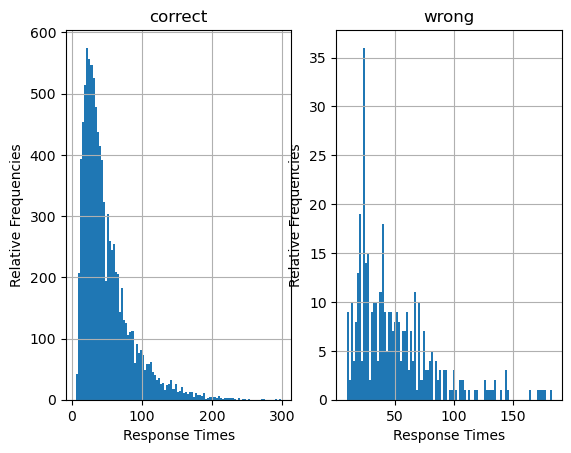

0.96


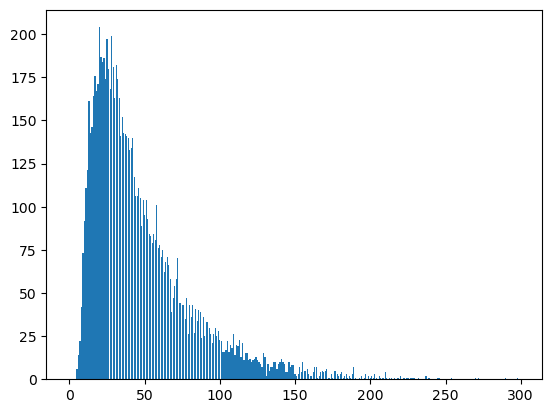

beware the elefant cause it punishes good stuff too hard


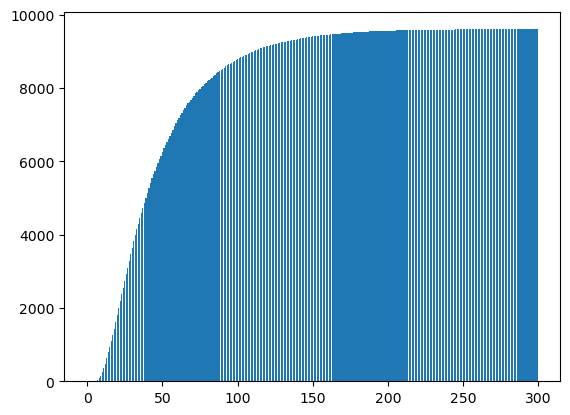

original params:
  sigma: 0.2
  drift: 0.01

init params:
  sigma: 0.23625192336608725
  drift: 0.1784346933558888



 11%|███████▊                                                                 | 10738/100000 [00:01<00:13, 6498.24it/s]

loss: 0.01690168394278625
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.23625192336608725
  drift: 0.023845195593840657



 21%|███████████████▌                                                         | 21270/100000 [00:03<00:12, 6213.89it/s]

loss: 0.0009211151857174201
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.23625192336608725
  drift: 0.023855460552782596



 31%|██████████████████████▌                                                  | 30876/100000 [00:05<00:11, 5933.23it/s]

... (11 outputs left out)

 91%|██████████████████████████████████████████████████████████████████▋      | 91275/100000 [00:15<00:01, 6648.93it/s]

loss: 0.0009211161373803272
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.23625192336608725
  drift: 0.02374121234363576



100%|████████████████████████████████████████████████████████████████████████| 100000/100000 [00:17<00:00, 5871.02it/s]


loss: 0.0009211161470326763
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.23625192336608725
  drift: 0.023748179945466425

wasted_runs 0


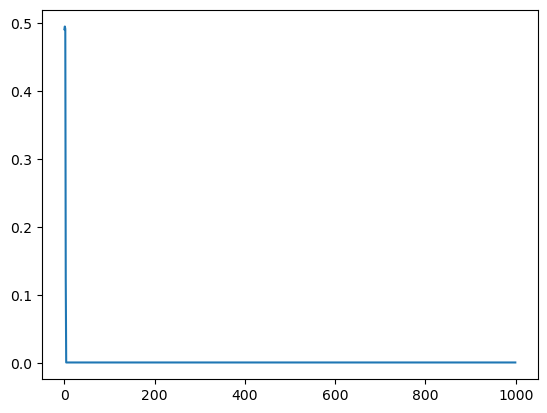

In [4]:
# so i guess the gradient for z is not 1




# 1st: there is gotta be a bug or a bias I did not understand at all: drift always becomes negative! 
# -> bug found: noise was not zero centered

# !!forgot to use cumulative dist!!

# 2nd: try using the normalized diff p_t,true-p_t,false
# 3rd: try our using ce of cheated distribution over batch
# misc: show ce

# generate dataset over t
z0=0.5
sigma=0.2
drift=0.01
max_steps=300
epochs=100000
lr=0.0001
n_data=10000

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
size0=data_dist[0].sum()/n_data
print(size0)


mode=np.argmax(data_dist[0,:])
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()
#fuck efficient coding for now
for i in range(1,len(data_dist[0])):
    data_dist[0,i]=np.sum(data_dist[0,i-1:i+1])
    
print("beware the elefant cause it punishes good stuff too hard")
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()

data_dist[0,:]/=data_dist[0,mode]

#plt.bar(np.arange(len(data_dist[0])),data_dist[0])
#plt.show()



data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]
size1=data_dist[1].sum()/n_data

mode=np.argmax(data_dist[1,:])
#fuck efficient coding for now
for i in range(1,len(data_dist[1])):
    data_dist[1,i]=np.sum(data_dist[1,i-1:i+1])

data_dist[1,:]/=data_dist[1,mode]





print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function_f=mean_l2_forward#
loss_function_b=mean_l2_backward#Node({},{},l2_forward, l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

too_fast=0
too_slow=0
good_runs=0

for epoch in tqdm(range(epochs)):
    z=z0
    z_old=z0
    for t in range(max_steps):
        z = train_model.forward([z, 0])#np.random.random()-0.5])#for now lets not train z0

        #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))
        
        #derivative=loss_function.back(None,-1)
        #print(derivative)
        #print(t)
        
        if z>=1 or (z<=0):
            if t==0:
                too_fast+=1
                break
            if z>=1:
                target = np.mean(data_dist[0,t-1:t+1])
                size=size0
            else:
                target = 1- np.mean(data_dist[1,t-1:t+1])
                size=size1
                
            losses.append(loss_function_f(target, None, (z_old, z)))
            
            #train_model.memory=[]
            derivative1, derivative2 = loss_function_b(target, None, (z_old, z), None)
            derivative1*=size
            derivative2*=size
            
            for t_back in range(t, 0-1, -1):
                
                derivative1=train_model.back(derivative1, t_back)[-1]#gradient for downstream/inputs will be last
                
                if t_back<t:
                    derivative2=train_model.back(derivative2, t_back)[-1]
                   
            good_runs+=1
            break
                
        z_old=z
        
    if t==max_steps-1:
        too_slow+=1
        
    train_model.update(lr)
    
    if not (epoch+1)%(epochs/10):
        print("loss:", np.mean(losses[-int(epochs/10):]))
        print("n too fast:", too_fast)
        print("n too slow:", too_slow)
        # self-check if insane
        print("n good_runs:", good_runs)
        too_fast=0
        too_slow=0
        good_runs=0
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

wasted_runs=epochs-len(losses)
if (len(losses)%100):
    losses = losses[:-(len(losses)%100)]
losses=np.array(losses)
print("wasted_runs",wasted_runs)
plt.plot(np.arange(int(len(losses)/100)), np.mean(np.split(losses, int(len(losses)/100)), axis=1))
plt.show()

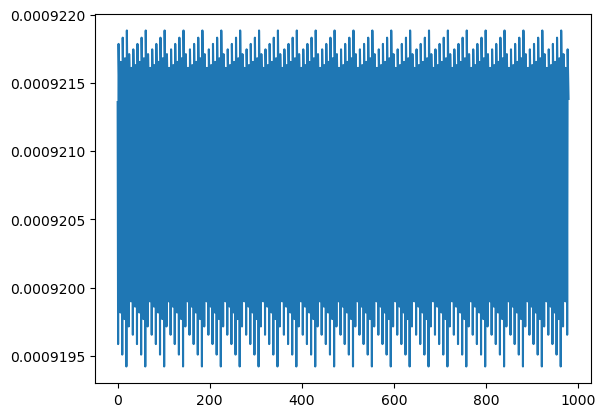

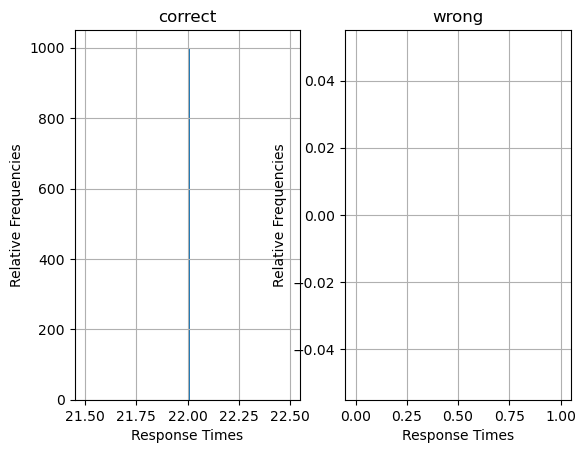

0.0
20
1.0


In [5]:
losses2=losses[2000:]
plt.plot(np.arange(int(len(losses2)/100)), np.mean(np.split(losses2, int(len(losses2)/100)), axis=1))
plt.show()

plot_dist_noiseless(train_model, max_steps)
print(data_dist[0,2])
print((data_dist[0]==1.0).argmax())
print(data_dist[0,(data_dist[0]==1.0).argmax()])

# Optimize z=1 at z_t, Noiseless eval (optional), lr-annealing
Few minor changes in contrast to last one: It seems sufficient to simply take the z value after reaching the threshold and comparing it to the cumulative, mode-normalized absolute frequency at the respective t. Additionally, a learning rate decay was implemented. This serves two purposes: testing a range of lr values in one go and giving the model a chance to, after an initial explorative phase, fine tune the values and reach convergence.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless

import pandas as pd
from tqdm import tqdm

In [2]:
class Node:
    def __init__(self, free_params, constants, operation, derivative):
        self.free_params_dict=dict(zip(free_params,np.arange(len(free_params))))
        self.free_params=np.array(list(free_params.values()))
        self.constants=constants
        self.memory=[]
        self.operation=operation
        self.derivative=derivative
        self.gradients=[]
        
    def forward(self,x):
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x)
    
    def back(self, df, t=None, v=False):
        """
        params:
            df (float): gradient of the next operation aka derivative of all that happens after this node
        """
        x=self.memory[t]
        #x=self.memory.pop()
        gradients=self.derivative(self.constants, self.free_params, x, df)
        self.gradients.append(gradients[:len(self.free_params)])
        if v==True:
            print(f"gradient at {t}: {self.gradients[-1]}")
            print(f"for inputs x",x)
        return gradients
    
    def update(self, lr, v=False):
        """
        terrible efficiency, todo: use dict only for mapping index to name and work on an array
        """
        #for key in np.arange(len(self.free_params)):
        #print(self.gradients)
        self.free_params-=lr*np.sum(self.gradients, axis=0)
        if v:
            print("updates:",-lr*np.sum(self.gradients, axis=0))
            print("individual updates: -",self.gradients)
        self.gradients=[]
    

In [4]:
def ddm_forward(constants, free_params, x):
    """
    expects x[0]=z and x[1]=noise
    """
    #print(f"{x[0]}+{x[1]}*{free_params[0]}+{free_params[1]}")
    return x[0]+x[1]*free_params[0]+free_params[1]

def ddm_backward(constants, free_params, x, df):
    """
    should give deriatives wrt z, drift and noise, nrt has to be somehow included in the loss function
    df (float): derivative of previous functions
    """
    #print(df, x)
    #return df*1, df*1, df*x[1] so far no z0
    return df*x[1], df*1, df*1#here

def l2_forward(constants, __, x):
    """
    x[0]=y, x[1]=true (convention: inputs first, constants last)
    """
    return 1/2*(x-constants)**2

def l2_backward(constants, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return x-constants

def mean_l2_forward(constants, __, x):
    return 1/2*(constants - (1/2 * x[0] + 1/2 * x[1]))**2

def mean_l2_backward(constants, __, x, ___):
    df = -1/2*constants + 1/4*x[0] + 1/4*x[1]
    return df, df
"""
f = 1/2(1 - (1/2 x0 + 1/2 x1))**2
f = 1/2(1 - 1/2x0 - 1/2x1)**2

g(h) = 1/2h**2
h(x0, x1) = 1 - 1/2x0 - 1/2x1

df/dx = dh/dx (x) * dg/dx (h)

dh/dx0 = - 1/2

dg/dx = h

df/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)
        = - 1/2 - 1/4 x0 - 1/4 x1

df/dx0 = 
"""

'\nf = 1/2(1 - (1/2 x0 + 1/2 x1))**2\nf = 1/2(1 - 1/2x0 - 1/2x1)**2\n\ng(h) = 1/2h**2\nh(x0, x1) = 1 - 1/2x0 - 1/2x1\n\ndf/dx = dh/dx (x) * dg/dx (h)\n\ndh/dx0 = - 1/2\n\ndg/dx = h\n\ndf/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)\n        = - 1/2 - 1/4 x0 - 1/4 x1\n\ndf/dx0 = \n'

      response    rt
0         -1.0  61.0
1         -1.0  48.0
2         -1.0  79.0
3         -1.0  81.0
4         -1.0  31.0
...        ...   ...
9995      -1.0  20.0
9996      -1.0  65.0
9997      -1.0  34.0
9998      -1.0  83.0
9999      -1.0  73.0

[10000 rows x 2 columns]


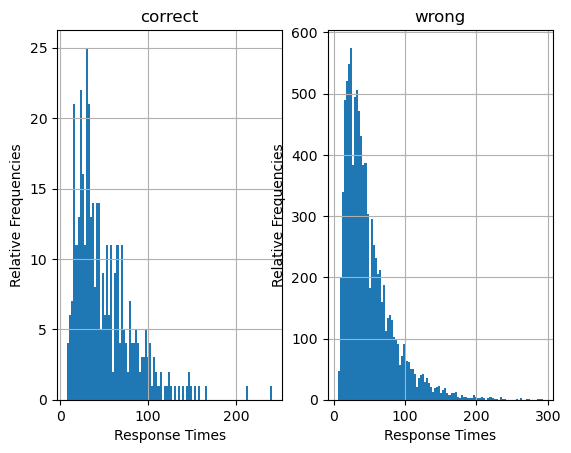

0.0386


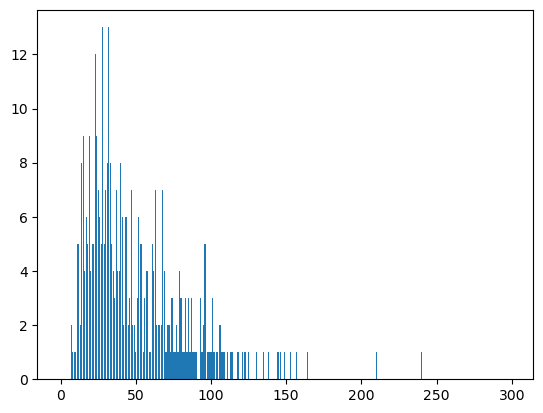

beware the elefant cause it punishes good stuff too hard


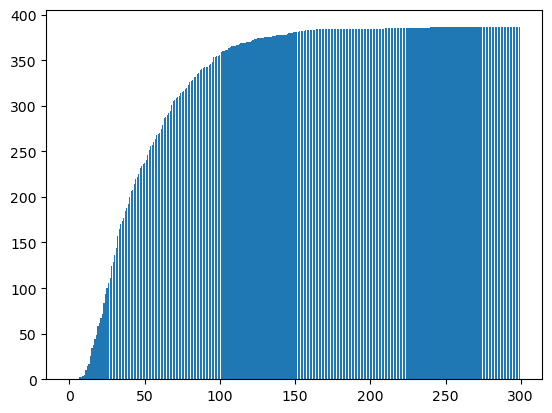

original params:
  sigma: 0.2
  drift: -0.01

init params:
  sigma: 0.41815358261485136
  drift: 0.1



 12%|████████▍                                                                | 11568/100000 [00:01<00:13, 6326.17it/s]

loss: 0.005742588499486598
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.41815358261485136
  drift: 0.017241379310520333



 21%|███████████████▎                                                         | 21045/100000 [00:03<00:11, 6781.50it/s]

loss: 1.458176565454788e-26
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.41815358261485136
  drift: 0.017241379310344862



 32%|███████████████████████                                                  | 31608/100000 [00:05<00:11, 6203.08it/s]

... (11 outputs left out)

 91%|██████████████████████████████████████████████████████████████████▊      | 91470/100000 [00:13<00:01, 8396.25it/s]

loss: 3.944304526105059e-31
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.41815358261485136
  drift: 0.017241379310344862



100%|████████████████████████████████████████████████████████████████████████| 100000/100000 [00:14<00:00, 6774.46it/s]


loss: 3.944304526105059e-31
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.41815358261485136
  drift: 0.017241379310344862

wasted_runs 0


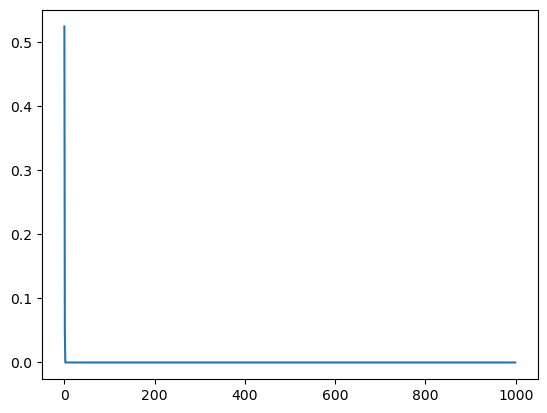

In [12]:

z0=0.5
sigma=0.2
drift=-0.01
max_steps=300
epochs=100000
lr=0.002
n_data=10000

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])

# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
size0=data_dist[0].sum()/n_data
print(size0)


mode=np.argmax(data_dist[0,:])
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()
#fuck efficient coding for now
for i in range(1,len(data_dist[0])):
    data_dist[0,i]=np.sum(data_dist[0,i-1:i+1])
    
print("beware the elefant cause it punishes good stuff too hard")
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()

data_dist[0,:]/=data_dist[0,mode]

#plt.bar(np.arange(len(data_dist[0])),data_dist[0])
#plt.show()



data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]
size1=data_dist[1].sum()/n_data

mode=np.argmax(data_dist[1,:])
#fuck efficient coding for now
for i in range(1,len(data_dist[1])):
    data_dist[1,i]=np.sum(data_dist[1,i-1:i+1])

data_dist[1,:]/=data_dist[1,mode]





print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

drift_train_init=0.1#np.random.random()-0.5
train_model=Node({"sigma": np.random.random(), "drift": drift_train_init}, dict(), ddm_forward, ddm_backward)

loss_function_f=l2_forward#mean_l2_forward#
loss_function_b=l2_backward#mean_l2_backward#Node({},{},l2_forward, l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]

too_fast=0
too_slow=0
good_runs=0

for epoch in tqdm(range(epochs)):
    z=z0
    z_old=z0
    for t in range(max_steps):
        z = train_model.forward([z, 0])#np.random.random()-0.5])#for now lets not train z0

        #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

        #losses.append(loss_function.forward([y, true]))
        
        #derivative=loss_function.back(None,-1)
        #print(derivative)
        #print(t)
        
        if z>=1 or (z<=0):
            if t==0:
                too_fast+=1
                break
            if z>=1:
                #target = np.mean(data_dist[0,t-1:t+1])#not sure why im taking the mean here
                target=data_dist[0,t]
                size=size0
            else:
                #target = 1- np.mean(data_dist[1,t-1:t+1])
                target=1-data_dist[1,t]
                size=size1
                
            losses.append(loss_function_f(target, None, z))
            
            #train_model.memory=[]
            derivative1 = loss_function_b(target, None, z, None)
            derivative1*=size
            #derivative2*=size
            
            for t_back in range(t, 0-1, -1):
                
                derivative1=train_model.back(derivative1, t_back)[-1]#gradient for downstream/inputs will be last
                
                '''if t_back<t:
                    derivative2=train_model.back(derivative2, t_back)[-1]'''
                   
            good_runs+=1
            break
                
        z_old=z
        
    if t==max_steps-1:
        too_slow+=1
        
    train_model.update(lr)
    
    if not (epoch+1)%(epochs/10):
        lr=lr*0.7
        print("loss:", np.mean(losses[-int(epochs/10):]))
        print("n too fast:", too_fast)
        print("n too slow:", too_slow)
        # self-check if insane
        print("n good_runs:", good_runs)
        too_fast=0
        too_slow=0
        good_runs=0
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

wasted_runs=epochs-len(losses)
if (len(losses)%100):
    losses = losses[:-(len(losses)%100)]
losses=np.array(losses)
print("wasted_runs",wasted_runs)
plt.plot(np.arange(int(len(losses)/100)), np.mean(np.split(losses, int(len(losses)/100)), axis=1))
plt.show()

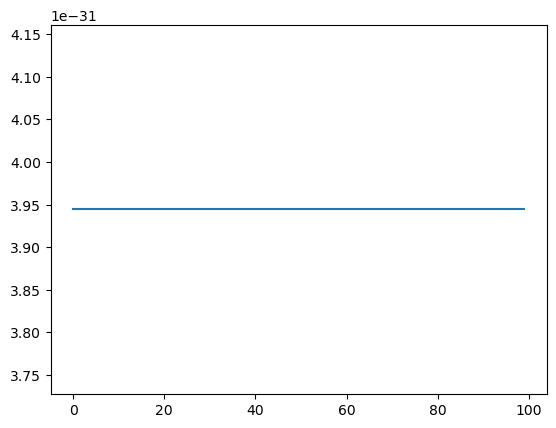

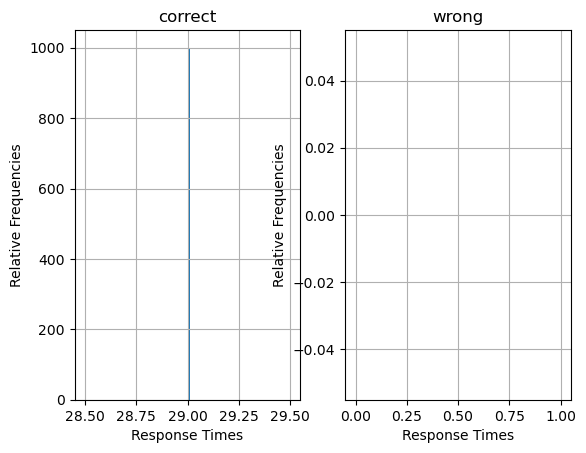

0.0
23
1.0


In [13]:
losses2=losses[90000:]
plt.plot(np.arange(int(len(losses2)/100)), np.mean(np.split(losses2, int(len(losses2)/100)), axis=1))
plt.show()

plot_dist_noiseless(train_model, max_steps)
print(data_dist[0,2])
print((data_dist[1]==1.0).argmax())
print(data_dist[1,(data_dist[1]==1.0).argmax()])

# Succesfully and Robustly predicting the Mode
This cell mainly introduces a lot of bug fixes from prior versions. The code can be used to reliably find a parameter fitting, that makes the model predict the mode of the train distribution (actually it finds the $t_mode+1$ because of an indexing bug). For training regimes that center around the outcomes of individual runs (in contrast to comparing the distribution of a whole batch of training runs with the distribution of the train data), this is the best we can hope for. This is because any single outcome maximizes the likelihood of stemming from the original distribution if and only if it predicts the mode of the original distribution (by definition of "mode").

An additional drawback is, that the model has no way of learning the marginal propabilities (aka the ratio between "correct"/upper threshold and "wrong"/lower threshold outcomes). So if the drift starts negative, the mode of the lower threshold rt distributions will be found, and vice versa. In theory, this should not happen with a more explorative start, because of the following fix: the gradients get scaled with the relative size of the predicted reaction vs the overall data. Hence, if a sufficient amount of runs for both outcomes get sampled, the changes that are introduced by the conditional distribution with the bigger absolute and summed up frequency should dominate.

warning: noise is not gaussian cause I'm stupid (does it matter though? I guess its not real DDM with uniform noise, but so what)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from ddm import DDM, generate_data_t, plot_dist, plot_dist_noiseless, generate_data_t_noiseless

import pandas as pd
from tqdm import tqdm

In [5]:
class Node:
    def __init__(self, free_params, constants, operation, derivative):
        self.free_params_dict=dict(zip(free_params,np.arange(len(free_params))))
        self.free_params=np.array(list(free_params.values()))
        self.constants=constants
        self.memory=[]
        self.operation=operation
        self.derivative=derivative
        self.gradients=[]
        
    def forward(self,x, v=False):
        self.memory.append(x)
        return self.operation(self.constants, self.free_params, x, v=v)
    
    def back(self, df, t=None, v=False):
        """
        params:
            df (float): gradient of the next operation aka derivative of all that happens after this node
        """
        x=self.memory[t]
        #x=self.memory.pop()
        gradients=self.derivative(self.constants, self.free_params, x, df)
        self.gradients.append(gradients[:len(self.free_params)])
        if v==True:
            print(f"gradient at {t}: {self.gradients[-1]}")
            print(f"for inputs x",x)
        return gradients
    
    def update(self, lr, v=False):
        """
        terrible efficiency, todo: use dict only for mapping index to name and work on an array
        """
        #for key in np.arange(len(self.free_params)):
        #print(self.gradients)
        if np.isnan(self.gradients).any():
            v=True
        self.free_params-=lr*np.sum(self.gradients, axis=0)
        if v:
            print("updates:",-lr*np.sum(self.gradients, axis=0))
            print("individual updates: ",-self.gradients)
            raise Exception
        self.gradients=[]
        self.memory=[]
    

In [6]:
def ddm_forward(constants, free_params, x, v=False):
    """
    expects x[0]=z and x[1]=noise
    """
    if v:
        print(f"{x[0]}+{x[1]}*{free_params[0]}+{free_params[1]}")
    return x[0]+x[1]*free_params[0]+free_params[1]

def ddm_backward(constants, free_params, x, df):
    """
    should give deriatives wrt noise, drift and z, nrt has to be somehow included in the loss function
    df (float): derivative of previous functions
    """
    #print(df, x)
    #return df*1, df*1, df*x[1] so far no z0
    return df*x[1], df*1, df*1#here

def l2_forward(constants, __, x):
    """
    x[0]=y, x[1]=true (convention: inputs first, constants last)
    """
    return 1/2*(x-constants)**2

def l2_backward(constants, __, x, ___):
    """
    gotta give gradient wrt input
    """
    return x-constants

def mean_l2_forward(constants, __, x):
    return 1/2*(constants - (1/2 * x[0] + 1/2 * x[1]))**2

def mean_l2_backward(constants, __, x, ___):
    df = -1/2*constants + 1/4*x[0] + 1/4*x[1]
    return df, df
"""
f = 1/2(1 - (1/2 x0 + 1/2 x1))**2
f = 1/2(1 - 1/2x0 - 1/2x1)**2

g(h) = 1/2h**2
h(x0, x1) = 1 - 1/2x0 - 1/2x1

df/dx = dh/dx (x) * dg/dx (h)

dh/dx0 = - 1/2

dg/dx = h

df/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)
        = - 1/2 - 1/4 x0 - 1/4 x1

df/dx0 = 
"""

'\nf = 1/2(1 - (1/2 x0 + 1/2 x1))**2\nf = 1/2(1 - 1/2x0 - 1/2x1)**2\n\ng(h) = 1/2h**2\nh(x0, x1) = 1 - 1/2x0 - 1/2x1\n\ndf/dx = dh/dx (x) * dg/dx (h)\n\ndh/dx0 = - 1/2\n\ndg/dx = h\n\ndf/dx0 = - 1/2 * (1 - 1/2x0 - 1/2x1)\n        = - 1/2 - 1/4 x0 - 1/4 x1\n\ndf/dx0 = \n'

      response     rt
0         -1.0  134.0
1          1.0   67.0
2          1.0   84.0
3          0.0    0.0
4          1.0   80.0
...        ...    ...
9995       1.0  298.0
9996      -1.0  239.0
9997       1.0  182.0
9998       1.0  198.0
9999       0.0    0.0

[10000 rows x 2 columns]


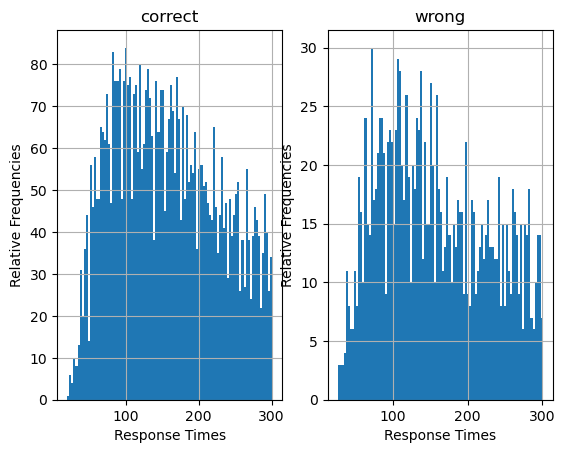

0.5084


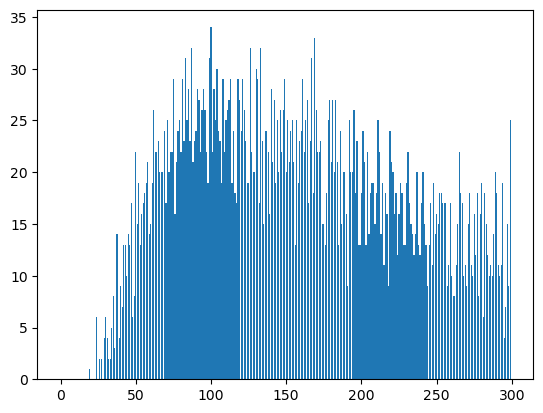

beware the elefant cause it punishes good stuff too hard


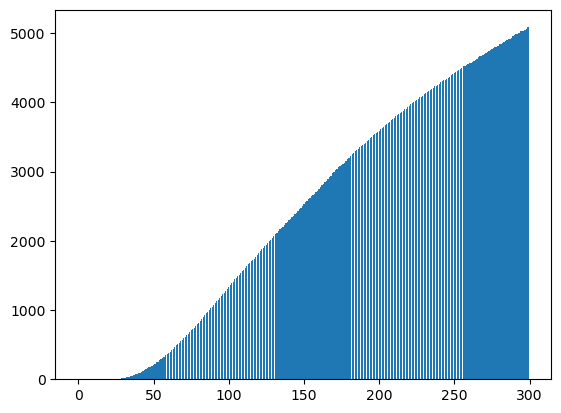

original params:
  sigma: 0.1
  drift: 0.001

init params:
  sigma: 0.06759694063366428
  drift: -0.44207725893816285



 10%|███████▏                                                                  | 9673/100000 [00:01<00:14, 6418.49it/s]

loss: 0.6005813623359224
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.03776743725018674
  drift: -0.00723732869348486



 20%|██████████████▊                                                          | 20331/100000 [00:07<00:49, 1622.74it/s]

loss: 0.02116767577978631
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: 0.0012297860314735218
  drift: -0.006364193692167929



 30%|██████████████████████▏                                                  | 30314/100000 [00:12<00:35, 1938.22it/s]

... (11 outputs left out)

 90%|█████████████████████████████████████████████████████████████████▉       | 90270/100000 [00:45<00:05, 1809.52it/s]

loss: 1.8447936859701572e-07
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: -1.0390519945425845e-08
  drift: -0.006329333785951031



100%|████████████████████████████████████████████████████████████████████████| 100000/100000 [00:51<00:00, 1947.50it/s]


loss: 1.106159619538687e-07
n too fast: 0
n too slow: 0
n good_runs: 10000
train params:
  sigma: -6.073912102608707e-08
  drift: -0.006329559833901521

wasted_runs 0


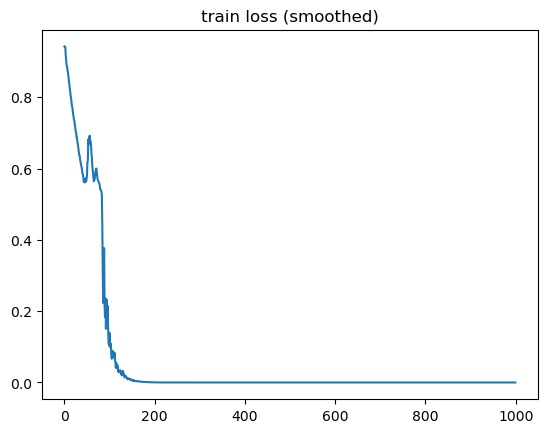

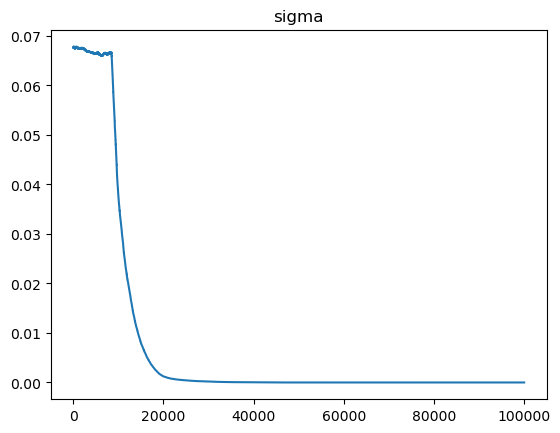

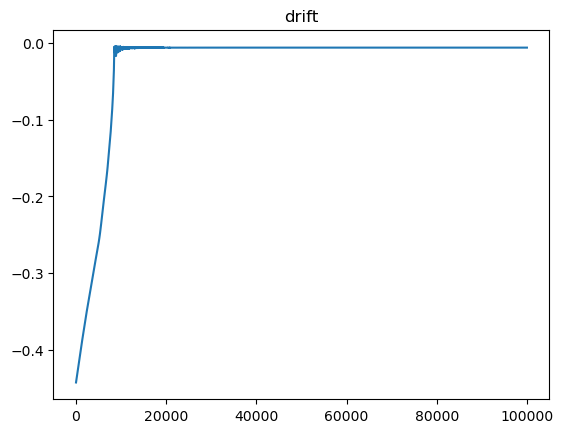

In [11]:

z0=0.5
sigma=0.1
drift=0.001
max_steps=300
epochs=100000#-00
lr=0.0001
n_data=10000

ddm_net=Node({"sigma": sigma, "drift": drift}, dict(), ddm_forward, ddm_backward)

dataset=generate_data_t(ddm_net, max_steps, n=n_data)
#print(dataset)
df=pd.DataFrame()
df["response"]=dataset[:,1]
df["rt"]=dataset[:,0]
ddm=DDM(0.5,0.2,0.1,10,(1,),"none", conditions=["s1, s2"])
ddm.log=df
print(df)
ddm.plot_histogram(conditions=[])


# (response, rt)
data_dist=np.zeros((2, max_steps))
#print(np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2)))

data_dist[0,:]=np.histogram(df.loc[df["response"]==1,"rt"], bins=np.arange(1,max_steps+2))[0]
size0=data_dist[0].sum()/n_data
print(size0)


mode=np.argmax(data_dist[0,:])
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()
#fuck efficient coding for now
for i in range(1,len(data_dist[0])):
    data_dist[0,i]=np.sum(data_dist[0,i-1:i+1])
    
print("beware the elefant cause it punishes good stuff too hard")
plt.bar(np.arange(len(data_dist[0])),data_dist[0])
plt.show()

data_dist[0,:]/=data_dist[0,mode]

#plt.bar(np.arange(len(data_dist[0])),data_dist[0])
#plt.show()



data_dist[1,:]=np.histogram(df.loc[df["response"]==-1,"rt"], bins=np.arange(1,max_steps+2))[0]
size1=data_dist[1].sum()/n_data

mode=np.argmax(data_dist[1,:])
#fuck efficient coding for now
for i in range(1,len(data_dist[1])):
    data_dist[1,i]=np.sum(data_dist[1,i-1:i+1])

gentleness=100
if not np.max(data_dist[1,:]):
    data_dist[1,:]=0#1/gentleness#1#0#np.max(data_dist[0,:])
    size1=1/gentleness
else:
    data_dist[1,:]/=data_dist[1,mode]





print(f"original params:\n  sigma: {ddm_net.free_params[ddm_net.free_params_dict['sigma']]}\n  drift: {ddm_net.free_params[ddm_net.free_params_dict['drift']]}\n")

train_model=Node({"sigma": np.random.random(), "drift": np.random.random()-0.5}, dict(), ddm_forward, ddm_backward)

loss_function_f=l2_forward#mean_l2_forward#
loss_function_b=l2_backward#mean_l2_backward#Node({},{},l2_forward, l2_backward)

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

losses=[]
losses_smooth=[]
drifts=[]
sigmas=[]

too_fast=0
too_slow=0
good_runs=0

for epoch in tqdm(range(epochs)):
    z=z0
    z_old=z0
    sigmas.append(train_model.free_params[train_model.free_params_dict['sigma']]) 
    drifts.append(train_model.free_params[train_model.free_params_dict['drift']])
    
    for t in range(max_steps):
        z = train_model.forward([z, np.random.random()-0.5])#np.random.random()-0.5])#for now lets not train z0
        
        if z>=1 or (z<=0) or (t==max_steps-1):
            if z>=1:
                #target = np.mean(data_dist[0,t-1:t+1])#not sure why im taking the mean here
                target=data_dist[0,t]
                size=size0
            else:
                #target = 1- np.mean(data_dist[1,t-1:t+1])
                target=1-data_dist[1,t]
                size=size1
                
            losses.append(loss_function_f(target, None, z))
            
            #train_model.memory=[]
            derivative1 = loss_function_b(target, None, z, None)
            derivative1*=size
            #derivative2*=size
            
            for t_back in range(t, 0-1, -1):
                
                derivative1=train_model.back(derivative1, t_back)[-1]#gradient for downstream/inputs will be last
                
                '''if t_back<t:
                    derivative2=train_model.back(derivative2, t_back)[-1]'''
                   
            if t==0:
                too_fast+=1
            else:
                good_runs+=1
            break
                
        z_old=z
        
    if t==max_steps-1:
        too_slow+=1
        
    train_model.update(lr)
    
    if not (epoch+1)%int(epochs/10):
        lr=lr*0.65
        print("loss:", np.mean(losses[-int(epochs/10):]))
        print("n too fast:", too_fast)
        print("n too slow:", too_slow)
        # self-check if insane
        print("n good_runs:", good_runs)
        too_fast=0
        too_slow=0
        good_runs=0
        print(f"train params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

wasted_runs=epochs-len(losses)
if (len(losses)%100):
    losses = losses[:-(len(losses)%100)]
losses=np.array(losses)
print("wasted_runs",wasted_runs)
plt.plot(np.arange(int(len(losses)/100)), np.mean(np.split(losses, int(len(losses)/100)), axis=1))
plt.title("train loss (smoothed)")
plt.show()
plt.plot(np.arange(len(sigmas)), sigmas)
plt.title("sigma")
plt.show()
plt.plot(np.arange(len(drifts)), drifts)
plt.title("drift")
plt.show()

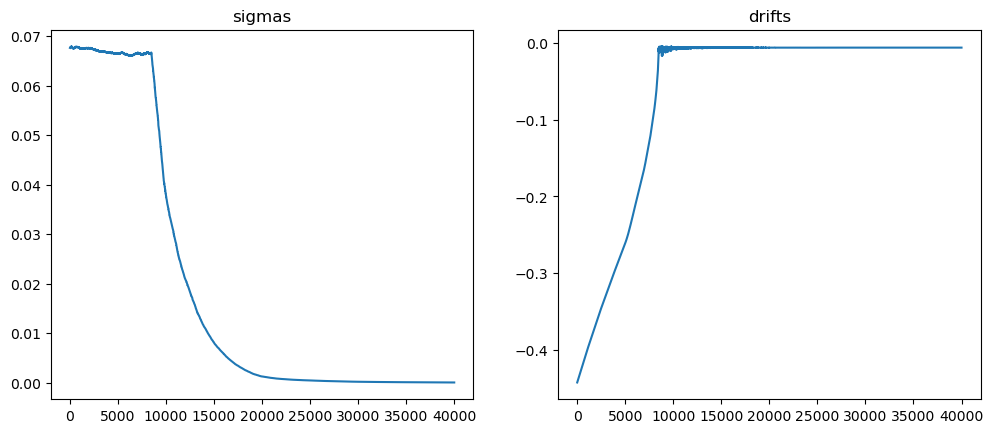

In [21]:
# plots for readme
fig, axs= plt.subplots(1,2)
fig.set_figwidth(12)
axs[0].plot(np.arange(40000), sigmas[:40000])
axs[0].title.set_text("sigmas")
axs[1].plot(np.arange(40000), drifts[:40000])
axs[1].title.set_text("drifts")
plt.show()

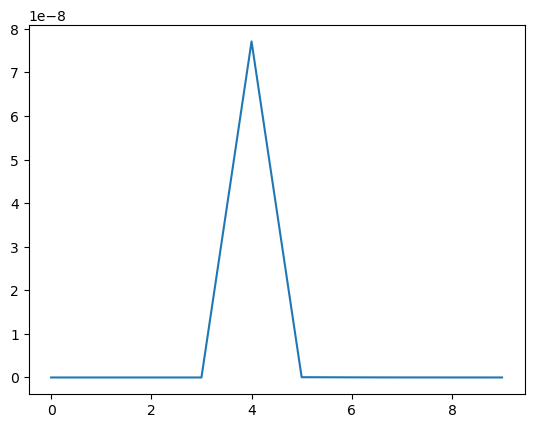

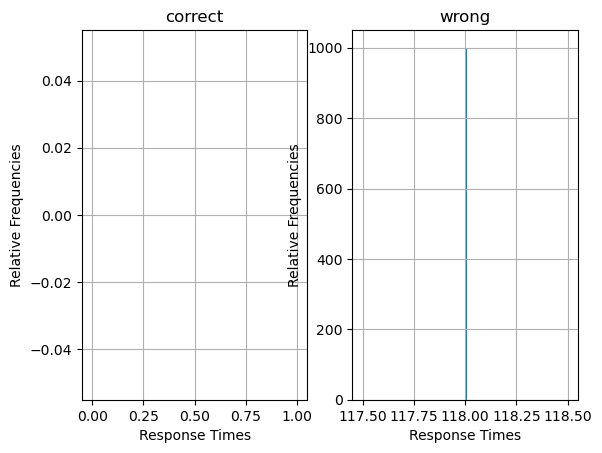

117


In [10]:
# Zoom in on the more interesting end of training and 

losses2=losses[-1000:]
plt.plot(np.arange(int(len(losses2)/100)), np.mean(np.split(losses2, int(len(losses2)/100)), axis=1))
plt.show()

neg=1# use neg=0 for comparing with dist of "correct" outcomes

plot_dist(train_model, max_steps)
print((data_dist[neg]==1.0).argmax())

## eval
Evaluate a single trainstep in a model for debugging (debuggers for notebooks never work for me...). This was extremely important for finding sign errors, memory leaks and comparable bugs in the backpropagation.

In [55]:
model_drift=train_model.free_params[train_model.free_params_dict['drift']]
model_sigma=train_model.free_params[train_model.free_params_dict['sigma']]

print(f"init params:\n  sigma: {train_model.free_params[train_model.free_params_dict['sigma']]}\n  drift: {train_model.free_params[train_model.free_params_dict['drift']]}\n")

z=z0
for t in range(max_steps):
    print(f"z at {t}: {z}")
    noise=np.random.random()-0.5
    print(f"plus noise:{noise}*sigma:{train_model.free_params[train_model.free_params_dict['sigma']]}")
    print(f"next should be:{z+model_drift+model_sigma*noise}")
    z = train_model.forward([z, np.random.random()-0.5])#for now lets not train z0
    #loss = loss_function.forward([z, data_dist[0,t],data_dist[1,t]])

    #losses.append(loss_function.forward([y, true]))

    #derivative=loss_function.back(None,-1)
    #print(derivative)
    #print(t)

    if z>=1 or (z<=0):
        print(f"final z: {z}")
        if t==0:
            too_fast+=1
            break
        if z>=1:
            target = np.mean(data_dist[0,t-1:t+1])
            size=size0
        else:
            target = 1- np.mean(data_dist[1,t-1:t+1])
            size=size1

        loss=loss_function_f(target, None, z)
        print("loss:",loss)

        #train_model.memory=[]
        derivative1= loss_function_b(target, None, z, None)
        derivative1/=size
        #derivative2/=size
        
        print(f"scaled derivatives of loss: {derivative1}")

        for t_back in range(t, 0-1, -1):
            print("t:",t_back)
            derivative1=train_model.back(derivative1, t_back, v=True)[0]

            '''if t_back<t:
                derivative2=train_model.back(derivative2, t_back, v=True)[0]'''

        break

    z_old=z

if t==max_steps-1:
    too_slow+=1

train_model.update(lr, v=True)

init params:
  sigma: 0.661324950487685
  drift: 0.003508636453002093

z at 0: 0.5
plus noise:0.4228292988820592*sigma:0.661324950487685
next should be:0.7831362016009225
z at 1: 0.6092538842935501
plus noise:-0.09719428727332402*sigma:0.661324950487685
next should be:0.5484855135278354
z at 2: 0.7267392769133466
plus noise:0.19393882519897054*sigma:0.661324950487685
next should be:0.8585044973386977
z at 3: 0.8694364689369102
plus noise:-0.45580751483086335*sigma:0.661324950487685
next should be:0.5715082232124769
z at 4: 0.7302139768726172
plus noise:0.20137941240412882*sigma:0.661324950487685
next should be:0.8668998432630189
z at 5: 0.7114598215565016
plus noise:-0.17429345006881247*sigma:0.661324950487685
next should be:0.5997038507724185
z at 6: 0.7663134657815197
plus noise:-0.08196965435301751*sigma:0.661324950487685
next should be:0.7156135246280199
z at 7: 0.9133641572232079
plus noise:0.2447092340136543*sigma:0.661324950487685
next should be:1.0787051157441692
final z: 1.131

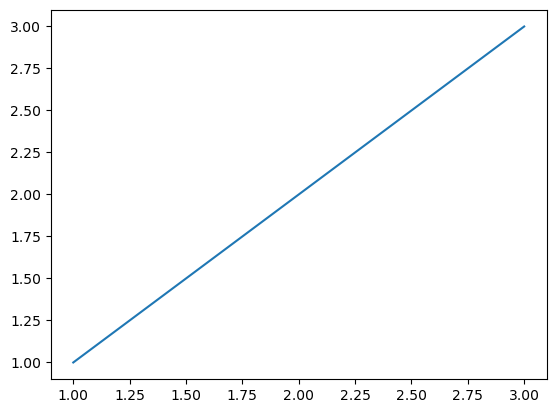

In [1]:
import matplotlib.pyplot as plt
plt.plot([1,2,3], [1,2,3])
plt.show()

# End
Use this as a bookmark for directly jumping to the end.